# Learning from unlabeled data
**Report section:** Unlabeled data

Data: cleaned via `src/data.py`, shared split, plus `unlabeled.csv`. Compares (a) baseline, (b) vocab fit on train+unlabeled, (c) pseudo-label thresholds, (d) self-training rounds.

In [1]:
# --- setup: make `src/` importable from anywhere (repo root, notebooks/, Kaggle/Colab clone) ---
import sys, time
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

QUICK = False  # True: 2,000-row starter file for fast debugging. False: full data (report numbers).

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED, set_seed, RESULTS_DIR, FIGURES_DIR
from src.data import get_split, load_test, load_unlabeled, load_train, get_cv_folds, xy
from src.features import build_features
from src.models import make_model
from src.evaluate import (auroc, cross_val_auroc, plot_roc, savefig, log_result,
                          save_predictions, predict_proba1)

set_seed(SEED)
SUFFIX = "_quick" if QUICK else ""   # keeps QUICK-mode outputs separate from real ones
from src.models import self_train, select_confident

In [3]:
train_df, val_df = get_split(quick=QUICK)
test_df = load_test()
X_tr, y_tr = xy(train_df)
X_va, y_va = xy(val_df)
unl_df = load_unlabeled()

# Optionally treat test texts as unlabeled data too (transductive). Test is the shifted
# distribution we actually care about, so this may help more than unlabeled.csv alone.
USE_TEST_AS_UNLABELED = False
X_unl = list(unl_df["text"]) + (list(test_df["text"]) if USE_TEST_AS_UNLABELED else [])
print(f"unlabeled pool: {len(X_unl)} texts")

results = []
def record(method, val_auc, **extra):
    row = {"method": method, "val_auroc": val_auc, **extra}
    results.append(row)
    log_result("unlabeled", {"method": method, "quick": QUICK, "test_as_unlabeled": USE_TEST_AS_UNLABELED,
                             **{k: v for k, v in extra.items() if k in ("threshold", "balance", "rounds")}},
               {k: v for k, v in row.items() if k not in ("method", "threshold", "balance", "rounds")})
    print(f"{method:40s} val AUROC = {val_auc:.4f}  {extra}")

[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=True)
split: train=8000 (AI=0.500)  val=2000 (AI=0.500)  quick=False clean=True


[test] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)


[unlabeled] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)
unlabeled pool: 3000 texts


## (a) Baseline: labelled data only

a_baseline                               val AUROC = 0.9563  {}


predicted AI share on unlabeled: 0.432
  confident at 0.8: 1223 / 3000
  confident at 0.9: 502 / 3000
  confident at 0.95: 146 / 3000
  confident at 0.99: 1 / 3000


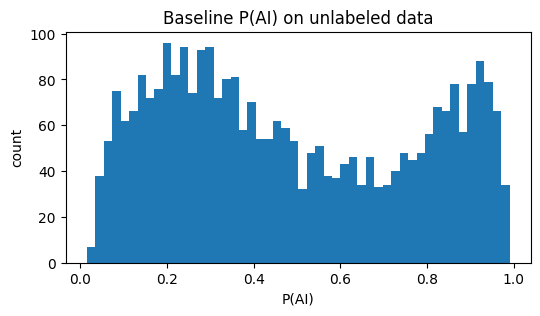

In [4]:
base = make_model("baseline").fit(X_tr, y_tr)
base_val = predict_proba1(base, X_va)
record("a_baseline", auroc(y_va, base_val))

p_unl = predict_proba1(base, X_unl)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(p_unl, bins=50)
ax.set(title="Baseline P(AI) on unlabeled data", xlabel="P(AI)", ylabel="count")
savefig(fig, "unlabeled_prob_hist" + SUFFIX)
print(f"predicted AI share on unlabeled: {(p_unl >= 0.5).mean():.3f}")
for t in (0.8, 0.9, 0.95, 0.99):
    print(f"  confident at {t}: {((p_unl >= t) | (p_unl <= 1 - t)).sum()} / {len(p_unl)}")

## (b) TF-IDF vocabulary/IDF fit on train + unlabeled

In [5]:
vocab_model = make_model("baseline", extra_texts=X_unl).fit(X_tr, y_tr)
record("b_vocab_train+unlabeled", auroc(y_va, predict_proba1(vocab_model, X_va)))

b_vocab_train+unlabeled                  val AUROC = 0.9556  {}


## (c) One-shot pseudo-labelling at different confidence thresholds

In [6]:
THRESHOLDS = [0.8, 0.9, 0.95, 0.99]
for t in THRESHOLDS:
    for balance in ([False, True] if t == 0.9 else [False]):
        idx, lab = select_confident(p_unl, t, balance=balance)
        m = make_model("baseline").fit(list(X_tr) + [X_unl[i] for i in idx], np.r_[y_tr, lab])
        record(f"c_pseudo_t{t}{'_bal' if balance else ''}", auroc(y_va, predict_proba1(m, X_va)),
               threshold=t, balance=balance, rounds=1, n_added=len(idx),
               frac_ai_added=float(lab.mean()) if len(idx) else np.nan)

c_pseudo_t0.8                            val AUROC = 0.9546  {'threshold': 0.8, 'balance': False, 'rounds': 1, 'n_added': 1223, 'frac_ai_added': 0.53556827473426}


c_pseudo_t0.9                            val AUROC = 0.9557  {'threshold': 0.9, 'balance': False, 'rounds': 1, 'n_added': 502, 'frac_ai_added': 0.6175298804780877}


c_pseudo_t0.9_bal                        val AUROC = 0.9558  {'threshold': 0.9, 'balance': True, 'rounds': 1, 'n_added': 384, 'frac_ai_added': 0.5}


c_pseudo_t0.95                           val AUROC = 0.9561  {'threshold': 0.95, 'balance': False, 'rounds': 1, 'n_added': 146, 'frac_ai_added': 0.7808219178082192}


c_pseudo_t0.99                           val AUROC = 0.9563  {'threshold': 0.99, 'balance': False, 'rounds': 1, 'n_added': 1, 'frac_ai_added': 1.0}


## (d) Multi-round self-training

In [7]:
ROUNDS = 2 if QUICK else 5
histories = []
for t, balance in [(0.9, False), (0.9, True)]:
    _, hist, pseudo = self_train(make_model("baseline"), X_tr, y_tr, X_unl, threshold=t,
                                 rounds=ROUNDS, balance=balance, X_val=X_va, y_val=y_va)
    hist = hist.assign(threshold=t, balance=balance)
    histories.append(hist)
    best = hist.loc[hist["val_auroc"].idxmax()]
    record(f"d_selftrain_t{t}{'_bal' if balance else ''}", float(hist["val_auroc"].iloc[-1]),
           threshold=t, balance=balance, rounds=ROUNDS, n_added=int(hist["n_pseudo_total"].iloc[-1]),
           best_round=int(best["round"]), best_round_val_auroc=float(best["val_auroc"]))

rounds_df = pd.concat(histories, ignore_index=True)
rounds_df.to_csv(RESULTS_DIR / f"unlabeled_selftrain_rounds{SUFFIX}.csv", index=False)
rounds_df

{'round': 0, 'n_pseudo_total': 0, 'val_auroc': 0.9563, 'n_added': 502, 'frac_ai_added': 0.6175}


{'round': 1, 'n_pseudo_total': 502, 'val_auroc': 0.9557, 'n_added': 43, 'frac_ai_added': 0.5116}


{'round': 2, 'n_pseudo_total': 545, 'val_auroc': 0.9557, 'n_added': 7, 'frac_ai_added': 0.5714}


{'round': 3, 'n_pseudo_total': 552, 'val_auroc': 0.9557, 'n_added': 1, 'frac_ai_added': 1.0}


{'round': 4, 'n_pseudo_total': 553, 'val_auroc': 0.9557, 'n_added': 0, 'frac_ai_added': nan}
d_selftrain_t0.9                         val AUROC = 0.9557  {'threshold': 0.9, 'balance': False, 'rounds': 5, 'n_added': 553, 'best_round': 0, 'best_round_val_auroc': 0.956313}


{'round': 0, 'n_pseudo_total': 0, 'val_auroc': 0.9563, 'n_added': 384, 'frac_ai_added': 0.5}


{'round': 1, 'n_pseudo_total': 384, 'val_auroc': 0.9558, 'n_added': 42, 'frac_ai_added': 0.5}


{'round': 2, 'n_pseudo_total': 426, 'val_auroc': 0.9558, 'n_added': 6, 'frac_ai_added': 0.5}


{'round': 3, 'n_pseudo_total': 432, 'val_auroc': 0.9558, 'n_added': 0, 'frac_ai_added': nan}
d_selftrain_t0.9_bal                     val AUROC = 0.9558  {'threshold': 0.9, 'balance': True, 'rounds': 5, 'n_added': 432, 'best_round': 0, 'best_round_val_auroc': 0.956313}


,round,n_pseudo_total,val_auroc,n_added,frac_ai_added,threshold,balance
0,0,0,0.956313,502,0.617530,0.9,False
1,1,502,0.955740,43,0.511628,0.9,False
2,2,545,0.955679,7,0.571429,0.9,False
3,3,552,0.955678,1,1.000000,0.9,False
4,4,553,0.955680,0,NaN,0.9,False
5,0,0,0.956313,384,0.500000,0.9,True
6,1,384,0.955829,42,0.500000,0.9,True
7,2,426,0.955841,6,0.500000,0.9,True
8,3,432,0.955838,0,NaN,0.9,True


PosixPath('/Users/allenlu/Desktop/aml/CS5785_GroupProject/figures/unlabeled_selftrain.png')

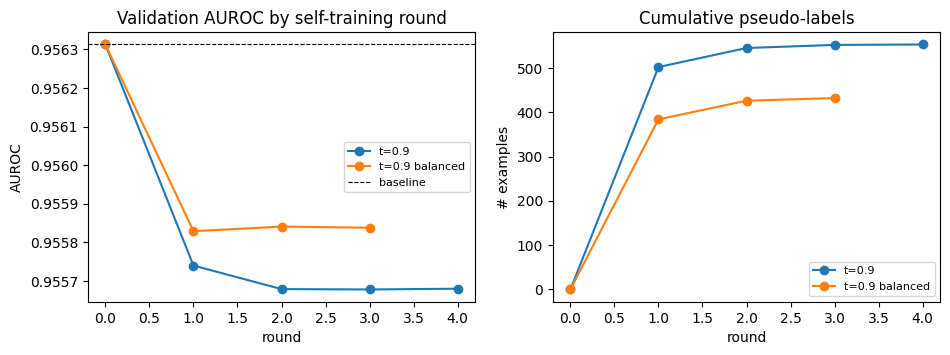

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for (t, bal), h in rounds_df.groupby(["threshold", "balance"]):
    lab = f"t={t}{' balanced' if bal else ''}"
    axes[0].plot(h["round"], h["val_auroc"], marker="o", label=lab)
    axes[1].plot(h["round"], h["n_pseudo_total"], marker="o", label=lab)
axes[0].axhline(results[0]["val_auroc"], color="k", ls="--", lw=0.8, label="baseline")
axes[0].set(title="Validation AUROC by self-training round", xlabel="round", ylabel="AUROC")
axes[1].set(title="Cumulative pseudo-labels", xlabel="round", ylabel="# examples")
for ax in axes: ax.legend(fontsize=8)
savefig(fig, "unlabeled_selftrain" + SUFFIX)

## Summary

In [9]:
summary = pd.DataFrame(results)
summary["delta_vs_baseline"] = summary["val_auroc"] - summary.loc[0, "val_auroc"]
summary.to_csv(RESULTS_DIR / f"unlabeled_summary{SUFFIX}.csv", index=False)
summary.sort_values("val_auroc", ascending=False)

,method,val_auroc,threshold,balance,rounds,n_added,frac_ai_added,best_round,best_round_val_auroc,delta_vs_baseline
6,c_pseudo_t0.99,0.956313,0.99,False,1.0,1.0,1.000000,NaN,NaN,1.110223e-16
0,a_baseline,0.956313,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00
5,c_pseudo_t0.95,0.956084,0.95,False,1.0,146.0,0.780822,NaN,NaN,-2.290000e-04
8,d_selftrain_t0.9_bal,0.955838,0.90,True,5.0,432.0,NaN,0.0,0.956313,-4.750000e-04
4,c_pseudo_t0.9_bal,0.955829,0.90,True,1.0,384.0,0.500000,NaN,NaN,-4.840000e-04
3,c_pseudo_t0.9,0.955740,0.90,False,1.0,502.0,0.617530,NaN,NaN,-5.730000e-04
7,d_selftrain_t0.9,0.955680,0.90,False,5.0,553.0,NaN,0.0,0.956313,-6.330000e-04
1,b_vocab_train+unlabeled,0.955644,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-6.690000e-04
2,c_pseudo_t0.8,0.954598,0.80,False,1.0,1223.0,0.535568,NaN,NaN,-1.715000e-03


## More experiments
- `USE_TEST_AS_UNLABELED = True` (check with staff first)
- Pseudo-label with the best model from model comparison instead of the baseline
- Soft labels: weight each pseudo-label by its confidence (`sample_weight`)
- Check whether gains hold on the test-like validation set (generalization notebook)